Design and implement a deep learning application for audio classification that incorporates Speech-to-Text (STT) and Text-to-Speech (TTS) using an appropriate deep learning architecture, and evaluate its performance using suitable metrics.

In [3]:
%pip install -q librosa soundfile scikit-learn matplotlib seaborn transformers datasets accelerate gTTS

In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import soundfile as sf
import torch

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("All core libraries imported successfully!")
print("NumPy version:", np.__version__)
print("Librosa version:", librosa.__version__)
print("PyTorch version:", torch.__version__)
print("Device:", "GPU" if torch.cuda.is_available() else "CPU")

All core libraries imported successfully!
NumPy version: 2.1.3
Librosa version: 0.11.0
PyTorch version: 2.11.0+cpu
Device: CPU


In [5]:
import os
import urllib.request
import zipfile

dataset_dir = "/content/ravdess"
os.makedirs(dataset_dir, exist_ok=True)

url = "https://zenodo.org/records/1188976/files/Audio_Speech_Actors_01-24.zip?download=1"
zip_path = "/content/ravdess_speech.zip"

if not os.path.exists(zip_path):
    print("Downloading RAVDESS speech dataset...")
    urllib.request.urlretrieve(url, zip_path)
    print("Download completed!")

if not any(
    name.endswith(".wav")
    for root, dirs, files in os.walk(dataset_dir)
    for name in files
):
    print("Extracting dataset...")
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(dataset_dir)
    print("Extraction completed!")

wav_files = []
for root, dirs, files in os.walk(dataset_dir):
    for file in files:
        if file.lower().endswith(".wav"):
            wav_files.append(os.path.join(root, file))

print("Total audio files:", len(wav_files))
print("Sample file:", wav_files[0] if wav_files else "No files found")

Download completed!
Extracting dataset...
Extraction completed!
Total audio files: 1440
Sample file: /content/ravdess/Actor_02/03-01-07-01-02-02-02.wav


In [6]:
import pandas as pd
import os

emotion_map = {
    "01": "neutral",
    "02": "calm",
    "03": "happy",
    "04": "sad",
    "05": "angry",
    "06": "fearful",
    "07": "disgust",
    "08": "surprised"
}

records = []

for filepath in wav_files:
    filename = os.path.basename(filepath)
    parts = filename.replace(".wav", "").split("-")

    if len(parts) == 7:
        emotion_code = parts[2]
        if emotion_code in emotion_map:
            records.append({
                "filepath": filepath,
                "emotion_code": emotion_code,
                "emotion": emotion_map[emotion_code],
                "actor": int(parts[6])
            })

df = pd.DataFrame(records)

print("Dataset shape:", df.shape)
print("\nEmotion distribution:")
print(df["emotion"].value_counts().sort_index())

print("\nFirst five records:")
display(df.head())

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (1440, 4)

Emotion distribution:
emotion
angry        192
calm         192
disgust      192
fearful      192
happy        192
neutral       96
sad          192
surprised    192
Name: count, dtype: int64

First five records:


,filepath,emotion_code,emotion,actor
0,/content/ravdess/Actor_02/03-01-07-01-02-02-02...,07,disgust,2
1,/content/ravdess/Actor_02/03-01-06-02-02-02-02...,06,fearful,2
2,/content/ravdess/Actor_02/03-01-05-01-02-02-02...,05,angry,2
3,/content/ravdess/Actor_02/03-01-03-01-01-01-02...,03,happy,2
4,/content/ravdess/Actor_02/03-01-01-01-01-01-02...,01,neutral,2



Missing values:
filepath        0
emotion_code    0
emotion         0
actor           0
dtype: int64


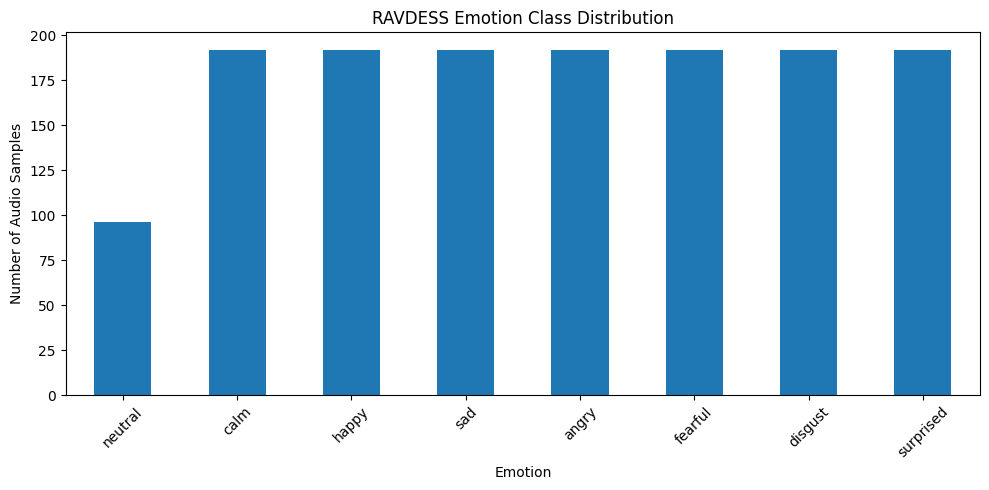

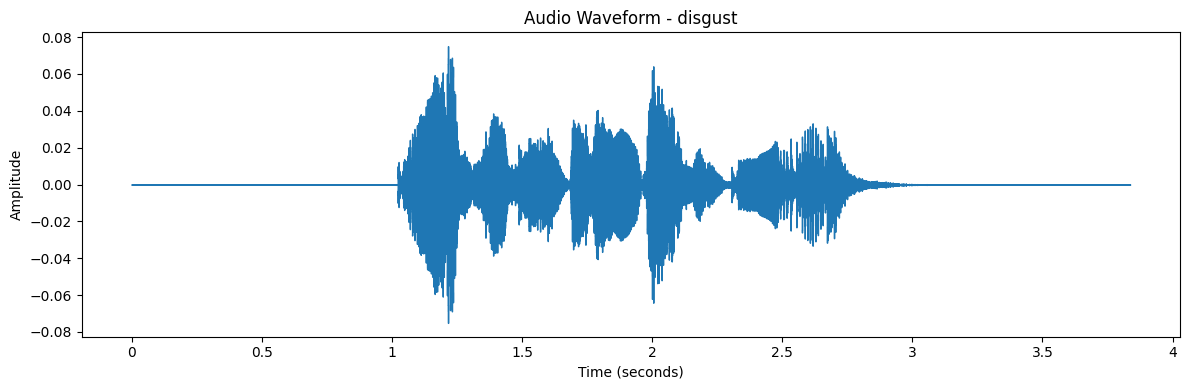

Sample audio duration: 3.84 seconds
Sample rate: 22050 Hz
Sample emotion: disgust


In [7]:
import matplotlib.pyplot as plt
import librosa
import librosa.display

# Plot emotion class distribution
plt.figure(figsize=(10, 5))
df["emotion"].value_counts().reindex([
    "neutral", "calm", "happy", "sad",
    "angry", "fearful", "disgust", "surprised"
]).plot(kind="bar")

plt.title("RAVDESS Emotion Class Distribution")
plt.xlabel("Emotion")
plt.ylabel("Number of Audio Samples")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Display waveform of one audio sample
sample_path = df.iloc[0]["filepath"]
audio, sr = librosa.load(sample_path, sr=22050)

plt.figure(figsize=(12, 4))
librosa.display.waveshow(audio, sr=sr)
plt.title(f"Audio Waveform - {df.iloc[0]['emotion']}")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.tight_layout()
plt.show()

print("Sample audio duration:", round(len(audio) / sr, 2), "seconds")
print("Sample rate:", sr, "Hz")
print("Sample emotion:", df.iloc[0]["emotion"])

In [8]:
import numpy as np
import librosa
from tqdm.auto import tqdm

SAMPLE_RATE = 22050
N_MFCC = 40

def extract_mfcc(filepath, n_mfcc=N_MFCC):
    audio, sr = librosa.load(filepath, sr=SAMPLE_RATE, duration=5.0)

    if len(audio) == 0:
        raise ValueError(f"Empty audio file: {filepath}")

    mfcc = librosa.feature.mfcc(
        y=audio,
        sr=sr,
        n_mfcc=n_mfcc,
        n_fft=2048,
        hop_length=512
    )

    # Mean and standard deviation over time
    features = np.concatenate([
        np.mean(mfcc, axis=1),
        np.std(mfcc, axis=1)
    ])

    return features.astype(np.float32)

X_list = []
y_list = []
failed_files = []

for row in tqdm(df.itertuples(index=False), total=len(df)):
    try:
        features = extract_mfcc(row.filepath)
        X_list.append(features)
        y_list.append(row.emotion)
    except Exception as e:
        failed_files.append((row.filepath, str(e)))

X = np.array(X_list, dtype=np.float32)
y = np.array(y_list)

print("Feature matrix shape:", X.shape)
print("Labels shape:", y.shape)
print("Failed files:", len(failed_files))
print("Features per recording:", X.shape[1] if len(X) else 0)

  0%|          | 0/1440 [00:00<?, ?it/s]

Feature matrix shape: (1440, 80)
Labels shape: (1440,)
Failed files: 0
Features per recording: 80


In [9]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from collections import Counter

# Convert emotion names into numeric labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Split before scaling to prevent data leakage
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

# Standardize using training data only
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train).astype(np.float32)
X_test = scaler.transform(X_test).astype(np.float32)

print("Classes:", list(label_encoder.classes_))
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

print("\nTraining class counts:")
print({
    label_encoder.classes_[int(k)]: int(v)
    for k, v in Counter(y_train).items()
})

print("\nTesting class counts:")
print({
    label_encoder.classes_[int(k)]: int(v)
    for k, v in Counter(y_test).items()
})

Classes: [np.str_('angry'), np.str_('calm'), np.str_('disgust'), np.str_('fearful'), np.str_('happy'), np.str_('neutral'), np.str_('sad'), np.str_('surprised')]
Training samples: 1152
Testing samples: 288
Training feature shape: (1152, 80)
Testing feature shape: (288, 80)

Training class counts:
{np.str_('happy'): 153, np.str_('disgust'): 154, np.str_('surprised'): 153, np.str_('angry'): 154, np.str_('sad'): 154, np.str_('neutral'): 77, np.str_('fearful'): 153, np.str_('calm'): 154}

Testing class counts:
{np.str_('sad'): 38, np.str_('calm'): 38, np.str_('happy'): 39, np.str_('angry'): 38, np.str_('neutral'): 19, np.str_('fearful'): 39, np.str_('disgust'): 38, np.str_('surprised'): 39}


In [10]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
num_classes = len(label_encoder.classes_)

# Convert features to tensors
X_train_tensor = torch.tensor(X_train, dtype=torch.float32).unsqueeze(1)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32).unsqueeze(1)

y_train_tensor = torch.tensor(y_train, dtype=torch.long)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

train_loader = DataLoader(
    train_dataset, batch_size=32, shuffle=True
)

test_loader = DataLoader(
    test_dataset, batch_size=64, shuffle=False
)

class AudioCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv1d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(2),

            nn.Conv1d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.MaxPool1d(2),

            nn.AdaptiveAvgPool1d(10),
            nn.Flatten()
        )

        self.classifier = nn.Sequential(
            nn.Linear(64 * 10, 128),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

model = AudioCNN(num_classes).to(device)

print(model)
print("\nDevice:", device)
print("Number of classes:", num_classes)
print("Total trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))

AudioCNN(
  (features): Sequential(
    (0): Conv1d(1, 32, kernel_size=(3,), stride=(1,), padding=(1,))
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv1d(32, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): AdaptiveAvgPool1d(output_size=10)
    (9): Flatten(start_dim=1, end_dim=-1)
  )
  (classifier): Sequential(
    (0): Linear(in_features=640, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.4, inplace=False)
    (3): Linear(in_features=128, out_features=8, bias=True)
  )
)

Device: cpu
Number of classes: 8
Total trainable parameters: 89608


In [11]:
import torch
import torch.nn as nn
import numpy as np

# Calculate class weights from training labels only
class_counts = np.bincount(y_train, minlength=num_classes)
class_weights = len(y_train) / (num_classes * class_counts)

class_weights_tensor = torch.tensor(
    class_weights, dtype=torch.float32
).to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

EPOCHS = 10

print("Loss function:", criterion.__class__.__name__)
print("Optimizer:", optimizer.__class__.__name__)
print("Initial learning rate:", optimizer.param_groups[0]["lr"])
print("Epochs:", EPOCHS)
print("\nClass weights:")
for name, weight in zip(label_encoder.classes_, class_weights):
    print(f"{name}: {weight:.3f}")

Loss function: CrossEntropyLoss
Optimizer: Adam
Initial learning rate: 0.001
Epochs: 10

Class weights:
angry: 0.935
calm: 0.935
disgust: 0.935
fearful: 0.941
happy: 0.941
neutral: 1.870
sad: 0.935
surprised: 0.941


In [12]:
import time

history = {
    "loss": [],
    "accuracy": []
}

start_time = time.time()

for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for inputs, labels in train_loader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(inputs)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    history["loss"].append(epoch_loss)
    history["accuracy"].append(epoch_accuracy)

    scheduler.step(epoch_loss)

    print(
        f"Epoch [{epoch + 1:02d}/{EPOCHS}] "
        f"Loss: {epoch_loss:.4f} | "
        f"Accuracy: {epoch_accuracy:.4f} | "
        f"LR: {optimizer.param_groups[0]['lr']:.6f}"
    )

elapsed = time.time() - start_time

print(f"\nTraining completed in {elapsed:.2f} seconds.")

Epoch [01/10] Loss: 1.9422 | Accuracy: 0.2422 | LR: 0.001000
Epoch [02/10] Loss: 1.7200 | Accuracy: 0.3247 | LR: 0.001000
Epoch [03/10] Loss: 1.5966 | Accuracy: 0.4028 | LR: 0.001000
Epoch [04/10] Loss: 1.4726 | Accuracy: 0.4497 | LR: 0.001000
Epoch [05/10] Loss: 1.4041 | Accuracy: 0.5052 | LR: 0.001000
Epoch [06/10] Loss: 1.2891 | Accuracy: 0.5104 | LR: 0.001000
Epoch [07/10] Loss: 1.2418 | Accuracy: 0.5521 | LR: 0.001000
Epoch [08/10] Loss: 1.1738 | Accuracy: 0.5651 | LR: 0.001000
Epoch [09/10] Loss: 1.1049 | Accuracy: 0.6276 | LR: 0.001000
Epoch [10/10] Loss: 0.9950 | Accuracy: 0.6545 | LR: 0.001000

Training completed in 7.43 seconds.


In [13]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

model.eval()

all_predictions = []
all_true_labels = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)

        outputs = model(inputs)
        predictions = outputs.argmax(dim=1).cpu().numpy()

        all_predictions.extend(predictions)
        all_true_labels.extend(labels.numpy())

# Calculate evaluation metrics
test_accuracy = accuracy_score(all_true_labels, all_predictions)
test_precision = precision_score(
    all_true_labels, all_predictions, average="macro", zero_division=0
)
test_recall = recall_score(
    all_true_labels, all_predictions, average="macro", zero_division=0
)
test_f1 = f1_score(
    all_true_labels, all_predictions, average="macro", zero_division=0
)

print("========== TEST RESULTS ==========")
print(f"Test Accuracy : {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")
print(f"Macro Precision: {test_precision:.4f}")
print(f"Macro Recall   : {test_recall:.4f}")
print(f"Macro F1-Score : {test_f1:.4f}")

print("\n========== CLASSIFICATION REPORT ==========")
print(classification_report(
    all_true_labels,
    all_predictions,
    labels=np.arange(num_classes),
    target_names=[str(c) for c in label_encoder.classes_],
    zero_division=0
))

========== TEST RESULTS ==========
Test Accuracy : 0.5868 (58.68%)
Macro Precision: 0.6116
Macro Recall   : 0.5853
Macro F1-Score : 0.5746

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

       angry       0.84      0.55      0.67        38
        calm       0.69      0.53      0.60        38
     disgust       0.66      0.66      0.66        38
     fearful       0.68      0.64      0.66        39
       happy       0.61      0.49      0.54        39
     neutral       0.21      0.58      0.31        19
         sad       0.52      0.29      0.37        38
   surprised       0.69      0.95      0.80        39

    accuracy                           0.59       288
   macro avg       0.61      0.59      0.57       288
weighted avg       0.64      0.59      0.59       288



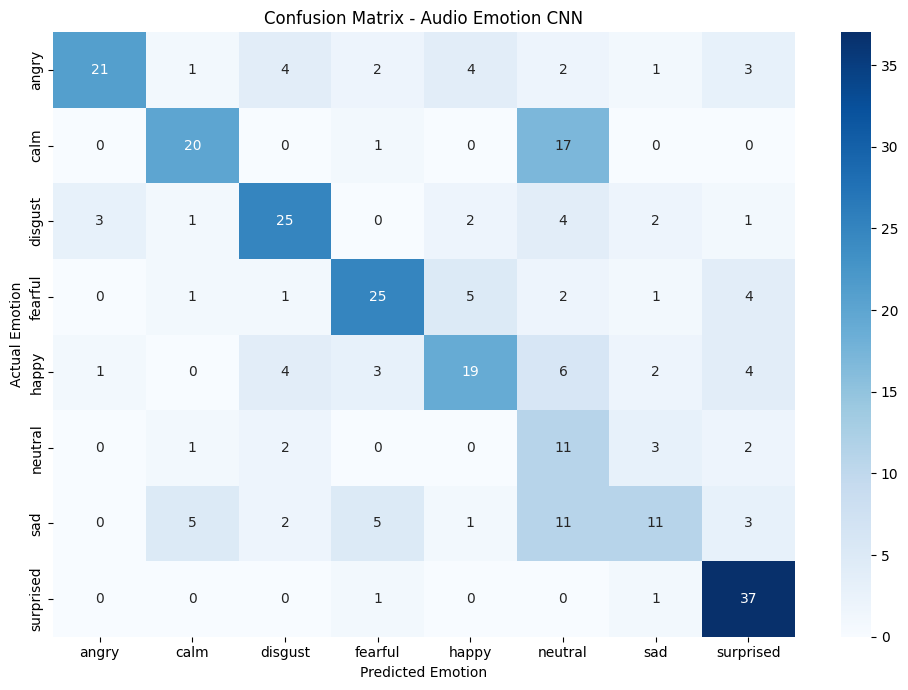

Rows represent actual emotions; columns represent predicted emotions.


In [14]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(
    all_true_labels,
    all_predictions,
    labels=np.arange(num_classes)
)

plt.figure(figsize=(10, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Confusion Matrix - Audio Emotion CNN")
plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")
plt.tight_layout()
plt.show()

print("Rows represent actual emotions; columns represent predicted emotions.")

In [15]:
import torch
from transformers import pipeline

stt_device = 0 if torch.cuda.is_available() else -1

stt_pipeline = pipeline(
    "automatic-speech-recognition",
    model="openai/whisper-tiny",
    device=stt_device
)

print("Whisper STT model loaded successfully!")
print("Device:", "GPU" if stt_device == 0 else "CPU")

config.json:   0%|          | 0.00/1.98k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  151MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/167 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/3.75k [00:00<?, ?B/s]

...

normalizer.json:   0%|          | 0.00/52.7k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/34.6k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.19k [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/185k [00:00<?, ?B/s]

Whisper STT model loaded successfully!
Device: CPU


In [16]:
# Select an audio file and run speech recognition
sample_stt_path = df.iloc[0]["filepath"]

stt_result = stt_pipeline(
    sample_stt_path,
    generate_kwargs={"task": "transcribe"}
)

print("Audio file:", os.path.basename(sample_stt_path))
print("Actual emotion label:", df.iloc[0]["emotion"])
print("Transcribed text:", repr(stt_result["text"]))

[transformers] Passing `generation_config` together with generation-related arguments=({'suppress_tokens', 'begin_suppress_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer WhisperTokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


Audio file: 03-01-07-01-02-02-02.wav
Actual emotion label: disgust
Transcribed text: ' Dogs are sitting by the door.'


In [17]:
from gtts import gTTS
from IPython.display import Audio, display

# Use the text produced by Whisper
text_to_speak = stt_result["text"].strip()

if not text_to_speak:
    text_to_speak = "No speech was recognized in the audio."

tts_output_path = "/content/tts_output.mp3"

tts = gTTS(text=text_to_speak, lang="en")
tts.save(tts_output_path)

print("Text to speak:", text_to_speak)
print("TTS audio saved to:", tts_output_path)

display(Audio(tts_output_path, autoplay=False))

Text to speak: Dogs are sitting by the door.
TTS audio saved to: /content/tts_output.mp3


In [18]:
from IPython.display import Audio, display
from gtts import gTTS
import os
import numpy as np
import torch

def audio_ai_application(audio_path):
    # 1. Extract features and classify emotion
    features = extract_mfcc(audio_path).reshape(1, -1)
    features = scaler.transform(features).astype(np.float32)

    input_tensor = torch.tensor(
        features, dtype=torch.float32
    ).unsqueeze(1).to(device)

    model.eval()
    with torch.no_grad():
        logits = model(input_tensor)
        probabilities = torch.softmax(logits, dim=1)
        predicted_index = logits.argmax(dim=1).item()
        confidence = probabilities[0, predicted_index].item()

    predicted_emotion = label_encoder.classes_[predicted_index]

    # 2. Speech-to-Text
    transcription = stt_pipeline(
        audio_path,
        generate_kwargs={"task": "transcribe"}
    )["text"].strip()

    if not transcription:
        transcription = "No speech was recognized."

    # 3. Text-to-Speech
    speech_text = (
        f"The predicted emotion is {predicted_emotion}. "
        f"The recognized speech is: {transcription}"
    )

    tts_path = "/content/integrated_tts.mp3"
    gTTS(text=speech_text, lang="en").save(tts_path)

    print("Predicted emotion:", predicted_emotion)
    print(f"Classification confidence: {confidence:.2%}")
    print("Transcription:", transcription)
    print("Generated speech:", speech_text)

    display(Audio(filename=tts_path))

    return {
        "emotion": predicted_emotion,
        "confidence": confidence,
        "transcription": transcription,
        "tts_path": tts_path
    }

print("Integrated Audio AI application is ready!")

Integrated Audio AI application is ready!


In [19]:
# Test the integrated application on one audio recording
test_audio_path = df.iloc[0]["filepath"]

print("Testing with:", os.path.basename(test_audio_path))
print("Actual dataset emotion:", df.iloc[0]["emotion"])
print("-" * 45)

result = audio_ai_application(test_audio_path)

Testing with: 03-01-07-01-02-02-02.wav
Actual dataset emotion: disgust
---------------------------------------------
Predicted emotion: disgust
Classification confidence: 60.96%
Transcription: Dogs are sitting by the door.
Generated speech: The predicted emotion is disgust. The recognized speech is: Dogs are sitting by the door.


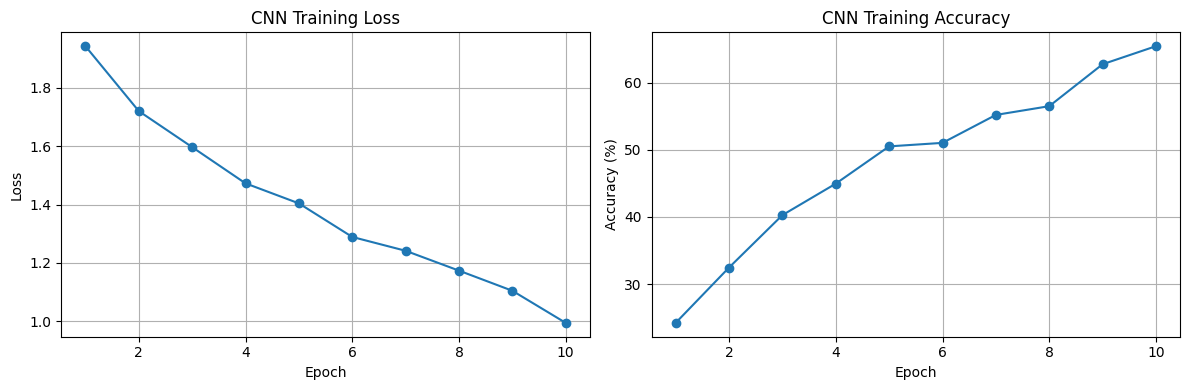

Initial training loss: 1.9422
Final training loss: 0.9950
Initial training accuracy: 24.22%
Final training accuracy: 65.45%
Test accuracy: 58.68%
Test macro F1-score: 0.5746


In [20]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    range(1, EPOCHS + 1),
    history["loss"],
    marker="o"
)
axes[0].set_title("CNN Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].grid(True)

axes[1].plot(
    range(1, EPOCHS + 1),
    [acc * 100 for acc in history["accuracy"]],
    marker="o"
)
axes[1].set_title("CNN Training Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].grid(True)

plt.tight_layout()
plt.show()

print(f"Initial training loss: {history['loss'][0]:.4f}")
print(f"Final training loss: {history['loss'][-1]:.4f}")
print(f"Initial training accuracy: {history['accuracy'][0]*100:.2f}%")
print(f"Final training accuracy: {history['accuracy'][-1]*100:.2f}%")
print(f"Test accuracy: {test_accuracy*100:.2f}%")
print(f"Test macro F1-score: {test_f1:.4f}")

In [21]:
import torch
import pickle
import os

model_path = "/content/audio_emotion_classifier.pth"
preprocessor_path = "/content/audio_preprocessing.pkl"

# Save trained CNN weights and configuration
torch.save({
    "model_state_dict": model.state_dict(),
    "num_classes": num_classes,
    "input_features": 80,
    "sample_rate": SAMPLE_RATE,
    "n_mfcc": N_MFCC,
    "classes": [str(c) for c in label_encoder.classes_],
    "test_accuracy": float(test_accuracy),
    "test_precision_macro": float(test_precision),
    "test_recall_macro": float(test_recall),
    "test_f1_macro": float(test_f1)
}, model_path)

# Save preprocessing objects
with open(preprocessor_path, "wb") as f:
    pickle.dump({
        "scaler": scaler,
        "label_encoder": label_encoder
    }, f)

print("Model saved:", model_path)
print("Preprocessing objects saved:", preprocessor_path)
print("Model file size:", round(os.path.getsize(model_path) / 1024, 2), "KB")
print("Preprocessor file size:", round(os.path.getsize(preprocessor_path) / 1024, 2), "KB")

print("\nFinal evaluation summary")
print(f"Accuracy:  {test_accuracy*100:.2f}%")
print(f"Precision: {test_precision:.4f}")
print(f"Recall:    {test_recall:.4f}")
print(f"F1-score:  {test_f1:.4f}")

Model saved: /content/audio_emotion_classifier.pth
Preprocessing objects saved: /content/audio_preprocessing.pkl
Model file size: 358.0 KB
Preprocessor file size: 2.76 KB

Final evaluation summary
Accuracy:  58.68%
Precision: 0.6116
Recall:    0.5853
F1-score:  0.5746
